# Laboratorio 03 — Reglas de asociación .


## 0. Dependencias

In [9]:
# Instala las bibliotecas necesarias.
%pip install pandas numpy matplotlib seaborn dbfread mlxtend scipy


Note: you may need to restart the kernel to use updated packages.


## 1. Documentación y configuración

In [10]:
# Importa las bibliotecas y crea la carpeta de resultados.
from pathlib import Path
import re, time, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dbfread import DBF
from dataclasses import dataclass, field
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
from IPython.display import display

pd.set_option('display.max_colwidth', 80)
ROOT = Path.cwd()
OUT = ROOT / 'resultados'
OUT.mkdir(exist_ok=True)
print('Directorio de trabajo:', ROOT)


Directorio de trabajo: c:\Lab03__\lab03


## 2. Descomprimir y localizar fuentes

In [11]:
# Localiza los archivos DBF en C:\archivos o en el ZIP.
ruta_pc = Path(r'C:\archivos')
ruta_proyecto = ROOT / 'datos' / 'archivos_extraidos'
zip_local = ROOT / 'datos' / 'archivos.zip'
def encontrar_dbf(carpeta):
    return sorted(p for p in carpeta.rglob('*') if p.is_file() and p.suffix.lower() == '.dbf') if carpeta.exists() else []
archivos = encontrar_dbf(ruta_pc)
if not archivos:
    if zip_local.exists():
        ruta_proyecto.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_local) as z:
            z.extractall(ruta_proyecto)
    archivos = encontrar_dbf(ruta_proyecto)
if not archivos:
    raise FileNotFoundError('No hay archivos DBF. Revisa C:\\archivos o datos/archivos.zip')
print(f'DBF encontrados: {len(archivos)}')
for a in archivos: print(a)


DBF encontrados: 13
C:\archivos\domingo\fc10032024.DBF
C:\archivos\domingo\fc24032024.DBF
C:\archivos\jueves\fc04042024.DBF
C:\archivos\jueves\fc14032024.DBF
C:\archivos\lunes\fc01042024.DBF
C:\archivos\lunes\fc11032024.DBF
C:\archivos\martes\fc02042024.DBF
C:\archivos\martes\fc12032024.DBF
C:\archivos\miercoles\fc03042024.DBF
C:\archivos\miercoles\fc13032024.DBF
C:\archivos\sabado\fc06042024.DBF
C:\archivos\sabado\fc09032024.DBF
C:\archivos\viernes\fc15032024.DBF


## 3. Lectura y parser de line-items

In [12]:
# Lee y reúne todos los archivos DBF.
partes = []
for archivo in archivos:
    try:
        registros = list(DBF(str(archivo), encoding='latin1', char_decode_errors='ignore', load=False))
    except Exception as e:
        raise RuntimeError(f'Error leyendo {archivo.name}: {e}. Compruebe la versión de dbfread.') from e
    temp = pd.DataFrame.from_records(registros)
    temp.columns = [str(c).upper() for c in temp.columns]
    temp['ARCHIVO'] = archivo.stem.upper()
    temp['DIA_CARPETA'] = archivo.parent.name
    patron = re.search(r'(\d{2})(\d{2})(\d{4})', archivo.stem)
    temp['FECHA_ARCHIVO'] = pd.to_datetime(''.join(patron.groups()), format='%d%m%Y') if patron else pd.NaT
    partes.append(temp)
raw = pd.concat(partes, ignore_index=True)
print('Registros totales:', len(raw))
print('Campos disponibles:', raw.columns.tolist())
display(raw.head(3))


Registros totales: 147413
Campos disponibles: ['FACNRO', 'CODTRA', 'CODIGOANT', 'CODIGO', 'REQ', 'CANT', 'DESC', 'PRECIO', 'TOTAL', 'IVA', 'CODCCO', 'SECUEN', 'CODCAJ', 'NROINT', 'ESTADO', 'DESCRI', 'COMIS', 'UNIDAD', 'CANTI2', 'DEVOL', 'COSPRO', 'DESCRI1', 'DESCRI2', 'TASIVA', 'PORIVA', 'TALLA', 'MESANRO', 'VENDEDOR', 'FRENTE', 'DESARRO', 'TIPOES', 'CUERDA', 'LOTE', 'DO', 'REMIS', 'PEDIDO', 'COSPROX', 'PDESCPF', 'VDESCPF', 'VLRDESC', 'FECVEN', 'PESOROLL', 'CODCCOE', 'NEGOCIO', 'COSPRUL', 'PORRETEN', 'VLRRETEN', 'IVAXVAL', 'IMPOCONS', 'CODDEP', '_NULLFLAGS', 'ARCHIVO', 'DIA_CARPETA', 'FECHA_ARCHIVO']


,FACNRO,CODTRA,CODIGOANT,CODIGO,REQ,CANT,DESC,PRECIO,TOTAL,IVA,...,COSPRUL,PORRETEN,VLRRETEN,IVAXVAL,IMPOCONS,CODDEP,_NULLFLAGS,ARCHIVO,DIA_CARPETA,FECHA_ARCHIVO
0,23102,FA,,7702535013212,,1.0,0.0,2521.01,2521.0,479.0,...,1400.59,None,None,0.0,NaN,None,b'\x01',FC10032024,domingo,2024-03-10
1,23102,FA,,78938533,,1.0,0.0,1848.74,1849.0,351.0,...,1382.35,None,None,0.0,NaN,None,b'\x01',FC10032024,domingo,2024-03-10
2,49554,FA,,7702354946944,,1.0,0.0,2941.18,2941.0,559.0,...,2083.33,None,None,0.0,NaN,None,b'\x01',FC10032024,domingo,2024-03-10


In [13]:
# Valida y prepara las columnas de ventas.
requeridos = ['FACNRO', 'CODIGO', 'DESCRI', 'CANT', 'PRECIO', 'TOTAL', 'IVA']
faltantes = [c for c in requeridos if c not in raw.columns]
if faltantes: raise ValueError(f'No se encontraron campos: {faltantes}')
ventas = raw[requeridos + ['ARCHIVO', 'FECHA_ARCHIVO', 'DIA_CARPETA']].copy()
for col in ['CANT', 'PRECIO', 'TOTAL', 'IVA']:
    ventas[col] = pd.to_numeric(ventas[col], errors='coerce')
for col in ['FACNRO', 'CODIGO', 'DESCRI']:
    ventas[col] = ventas[col].fillna('').astype(str).str.strip()
ventas['ID_FACTURA'] = ventas['ARCHIVO'] + '|' + ventas['FACNRO']
ventas['PRODUCTO_ID'] = ventas['CODIGO']
print('Líneas sin número de factura:', (ventas['FACNRO']=='').sum())
print('Cantidad <= 0:', (ventas['CANT']<=0).sum())
print('Importe <= 0:', (ventas['TOTAL']<=0).sum())
display(ventas.head())


Líneas sin número de factura: 0
Cantidad <= 0: 0
Importe <= 0: 110


,FACNRO,CODIGO,DESCRI,CANT,PRECIO,TOTAL,IVA,ARCHIVO,FECHA_ARCHIVO,DIA_CARPETA,ID_FACTURA,PRODUCTO_ID
0,23102,7702535013212,BRISA LIMON-MANZANA 600ML ...,1.0,2521.01,2521.0,479.0,FC10032024,2024-03-10,domingo,FC10032024|23102,7702535013212
1,23102,78938533,TIC TAC 16GR ...,1.0,1848.74,1849.0,351.0,FC10032024,2024-03-10,domingo,FC10032024|23102,78938533
2,49554,7702354946944,VIVE 100 LITRO ...,1.0,2941.18,2941.0,559.0,FC10032024,2024-03-10,domingo,FC10032024|49554,7702354946944
3,49554,7702303006491,LUCKY GIN X 10 ...,1.0,4873.95,4874.0,926.0,FC10032024,2024-03-10,domingo,FC10032024|49554,7702303006491
4,49555,7702090060553,CRISTAL ALOE 330 ML ...,1.0,2184.87,2185.0,415.0,FC10032024,2024-03-10,domingo,FC10032024|49555,7702090060553


### 3.1. Objetos LineItem y Factura

In [14]:
# Crea los objetos LineItem y Factura.
@dataclass
class LineItem:
    codigo: str
    nombre: str
    cantidad: float
    precio_unitario: float
    subtotal: float
    impuesto: float

@dataclass
class Factura:
    numero: str
    fecha: object
    total_lineas: float
    total_impuesto_lineas: float
    cantidad_total_items: float
    items: list[LineItem] = field(default_factory=list)

def crear_facturas(df):
    resultado = []
    df = df[df['FACNRO'] != '']
    for id_factura, grupo in df.groupby('ID_FACTURA', sort=False):
        items = [LineItem(str(r.CODIGO), str(r.DESCRI), float(r.CANT) if pd.notna(r.CANT) else 0.0,
                          float(r.PRECIO) if pd.notna(r.PRECIO) else 0.0,
                          float(r.TOTAL) if pd.notna(r.TOTAL) else 0.0,
                          float(r.IVA) if pd.notna(r.IVA) else 0.0)
                 for r in grupo.itertuples()]
        resultado.append(Factura(id_factura, grupo['FECHA_ARCHIVO'].iloc[0],
                                 sum(x.subtotal for x in items), sum(x.impuesto for x in items),
                                 sum(x.cantidad for x in items), items))
    return resultado
facturas = crear_facturas(ventas)
print('Facturas construidas:', len(facturas))
print('Ejemplo:', facturas[0] if facturas else 'No hay facturas')


Facturas construidas: 68514
Ejemplo: Factura(numero='FC10032024|23102', fecha=Timestamp('2024-03-10 00:00:00'), total_lineas=4370.0, total_impuesto_lineas=830.0, cantidad_total_items=2.0, items=[LineItem(codigo='7702535013212', nombre='BRISA LIMON-MANZANA 600ML                                                                                                                                                                                                                                    B', cantidad=1.0, precio_unitario=2521.01, subtotal=2521.0, impuesto=479.0), LineItem(codigo='78938533', nombre='TIC TAC 16GR                                                                                                                                                                                                                                                 B', cantidad=1.0, precio_unitario=1848.74, subtotal=1849.0, impuesto=351.0)])


## 4. Análisis descriptivo (punto 3 del enunciado)

In [15]:
# Calcula las estadísticas generales de las facturas.
validas = ventas[(ventas['FACNRO'] != '') & (ventas['PRODUCTO_ID'] != '') &
                 (ventas['CANT'] > 0)].copy()
por_factura = validas.groupby('ID_FACTURA').agg(
    unidades=('CANT', 'sum'),
    lineas=('PRODUCTO_ID', 'size'),
    productos_distintos=('PRODUCTO_ID','nunique'),
    importe=('TOTAL', 'sum'),
    impuesto=('IVA','sum'))
resumen = pd.Series({
    'Registros fuente': len(ventas), 'Líneas válidas positivas': len(validas),
    'Facturas con compras positivas': len(por_factura),
    'Promedio unidades por factura': por_factura['unidades'].mean(),
    'Promedio productos distintos por factura': por_factura['productos_distintos'].mean(),
    'Máximo unidades por factura': por_factura['unidades'].max(),
    'Máximo productos distintos por factura': por_factura['productos_distintos'].max(),
    'Unidades totales': validas['CANT'].sum(), 'Venta línea total': validas['TOTAL'].sum(),
    'Productos distintos': validas['PRODUCTO_ID'].nunique()})
display(resumen.to_frame('Valor'))
resumen.to_csv(OUT / 'resumen_general.csv', header=['valor'], encoding='utf-8-sig')


,Valor
Registros fuente,1.474130e+05
Líneas válidas positivas,1.474130e+05
Facturas con compras positivas,6.851400e+04
Promedio unidades por factura,6.797151e+00
Promedio productos distintos por factura,2.085851e+00
Máximo unidades por factura,5.710000e+03
Máximo productos distintos por factura,4.900000e+01
Unidades totales,4.657000e+05
Venta línea total,9.955219e+08
Productos distintos,1.275000e+03


### 4.a. Distribución por fecha y comprobación de hora

Campos posiblemente temporales: ['FECVEN', 'FECHA_ARCHIVO']
FECVEN ejemplos: ['', '', '', '', '']
FECHA_ARCHIVO ejemplos: ['2024-03-10', '2024-03-10', '2024-03-10', '2024-03-10', '2024-03-10']


,facturas,unidades,ingreso
FECHA_ARCHIVO,,,
2024-03-09,5219,31511.0,6.600541e+07
2024-03-10,5399,32468.0,6.809874e+07
2024-03-11,5949,35026.0,7.426028e+07
2024-03-12,6514,50348.0,1.052781e+08
2024-03-13,7114,52668.0,1.109996e+08
2024-03-14,7689,63053.0,1.322432e+08
2024-03-15,8428,66125.0,1.406278e+08
2024-03-24,12993,84725.0,1.858101e+08
2024-04-01,533,5665.0,1.212058e+07


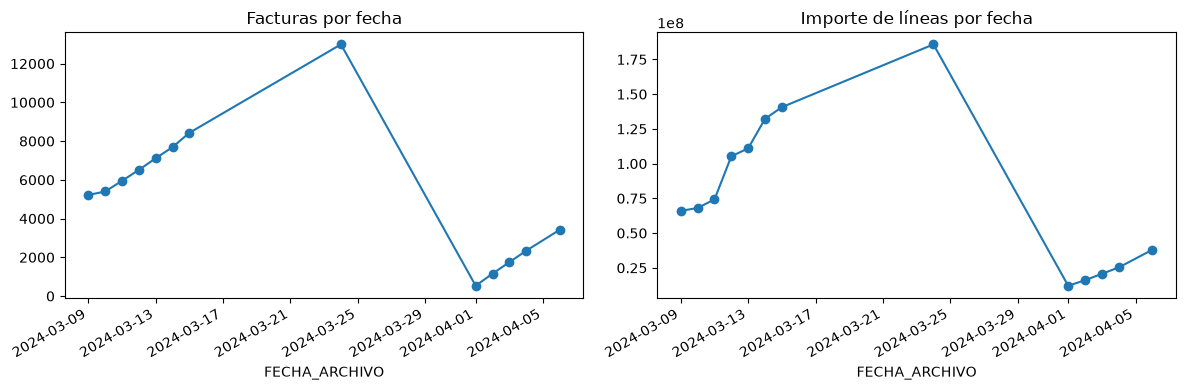

In [16]:
# Revisa si existen horas y grafica las ventas por fecha.
candidatos_hora = [c for c in raw.columns if any(p in c for p in ['HORA','TIME','FECHA','FEC','TIMESTAMP'])]
print('Campos posiblemente temporales:', candidatos_hora)
for c in candidatos_hora:
    print(c, 'ejemplos:', raw[c].dropna().astype(str).head(5).tolist())
resumen_fecha = validas.groupby('FECHA_ARCHIVO').agg(
    facturas=('ID_FACTURA','nunique'), unidades=('CANT','sum'), ingreso=('TOTAL','sum'))
display(resumen_fecha)
resumen_fecha.to_csv(OUT/'distribucion_por_fecha.csv', encoding='utf-8-sig')
fig, axes = plt.subplots(1,2, figsize=(12,4))
resumen_fecha['facturas'].plot(ax=axes[0], marker='o', title='Facturas por fecha')
resumen_fecha['ingreso'].plot(ax=axes[1], marker='o', title='Importe de líneas por fecha')
plt.tight_layout(); plt.savefig(OUT/'distribucion_fecha.png', dpi=160); plt.show()


### 4.b/c. Producto más vendido; comparación con Top 10

,unidades,apariciones,valor,descripcion
PRODUCTO_ID,,,,
35,21099.0,7203,52787800.0,EMPANADAS ...
32,8543.0,218,296844.0,DESECHABLE X UND ...
7702004003508,8180.0,323,14979358.0,CERVEZA CLUB COLOMBIA 330 ML ...
1025,8109.0,2967,21594128.0,PASTELES. PALITOS ...
7702090029864,7997.0,2609,14444539.0,JUGO HIT 500 ML ...
116,6857.0,1913,10094490.0,SANDWICH SENCILLO ...
7702004007834,6779.0,247,12510462.0,CERVEZA POKER 355ML ...
7707298440947,6676.0,2050,2436468.0,CANDYRANCH 13GR ...
7702004011183,5501.0,191,8641511.0,CERVEZA REDS LATA 269 ...


Producto más vendido: EMPANADAS                                                                                                                                                                                                                                                    B unidades: 21099.0


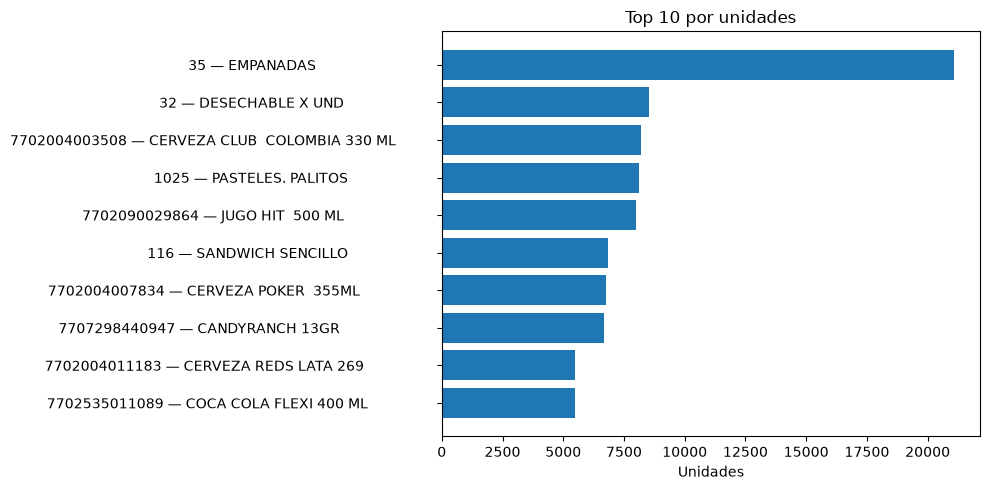

In [17]:
# Obtiene y grafica el Top 10 de productos.
catalogo = (validas.groupby('PRODUCTO_ID')['DESCRI']
            .agg(lambda s: s.value_counts().index[0] if len(s) else '').to_dict())
top = (validas.groupby('PRODUCTO_ID').agg(unidades=('CANT','sum'),
        apariciones=('ID_FACTURA','nunique'), valor=('TOTAL','sum'))
       .sort_values('unidades', ascending=False))
top['descripcion'] = top.index.map(catalogo)
display(top.head(10))
print('Producto más vendido:', top.iloc[0]['descripcion'], 'unidades:', top.iloc[0]['unidades'])
top.head(10).to_csv(OUT/'top10.csv', encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(10,5))
labels=[f'{i} — {str(r.descripcion)[:38]}' for i,r in top.head(10).iterrows()]
ax.barh(labels[::-1], top.head(10)['unidades'].iloc[::-1])
ax.set(xlabel='Unidades', title='Top 10 por unidades')
plt.tight_layout(); plt.savefig(OUT/'top10.png', dpi=160); plt.show()


### 4.d. Producto menos vendido y productos acompañantes

In [18]:
# Analiza el producto menos vendido y sus acompañantes.
menores = top.sort_values(['unidades','apariciones'], ascending=True)
display(menores.head(10))
menos_codigo = menores.index[0]
compras_menos = validas.loc[validas['PRODUCTO_ID']==menos_codigo,'ID_FACTURA'].unique()
lineas_menos = validas[validas['ID_FACTURA'].isin(compras_menos)]
acompanantes = lineas_menos.loc[lineas_menos['PRODUCTO_ID']!=menos_codigo].groupby('PRODUCTO_ID').agg(
    facturas=('ID_FACTURA','nunique'), unidades=('CANT','sum')).sort_values('facturas',ascending=False)
acompanantes['descripcion'] = acompanantes.index.map(catalogo)
print('Producto menos vendido:', menos_codigo, catalogo.get(menos_codigo),
      '| facturas de aparición:', len(compras_menos))
print('Comprado solo en', sum(por_factura.loc[compras_menos,'productos_distintos']==1), 'facturas')
print('Comprado con otros en', sum(por_factura.loc[compras_menos,'productos_distintos']>1), 'facturas')
print('Fechas en que aparece:')
display(validas[validas['PRODUCTO_ID']==menos_codigo].groupby('FECHA_ARCHIVO').agg(
    facturas=('ID_FACTURA','nunique'),unidades=('CANT','sum')))
display(acompanantes.head(15))


,unidades,apariciones,valor,descripcion
PRODUCTO_ID,,,,
7702025145591,1.0,1,2600.0,TACO DUCALES MINI ...
325,1.0,1,400.0,FOSFOROS ...
7702993045909,1.0,1,2017.0,SNACKS ORIGAMI 45 GR ...
7707231852844,1.0,1,1933.0,YOGURT CON FRUTA PESLAC 150 GR ...
7707319063841,1.0,1,3361.0,BOLSA PEQUEÑA DELIRIO ...
7709068308280,1.0,1,2101.0,CINTA DE ENMASCARAR DELGADA ...
192568962002,1.0,1,9160.0,KIDSMANIA CRAWLY CREW ...
7707319063872,1.0,1,7479.0,BOLSA DELIRIO GRANDE ...
7702001169337,1.0,1,0.0,


Producto menos vendido: 7702025145591 TACO DUCALES MINI                                                                                                                                                                                                                                             | facturas de aparición: 1
Comprado solo en 0 facturas
Comprado con otros en 1 facturas
Fechas en que aparece:


,facturas,unidades
FECHA_ARCHIVO,,
2024-03-24,1,1.0


,facturas,unidades,descripcion
PRODUCTO_ID,,,
1025,1,2.0,PASTELES. PALITOS ...
7702001158225,1,2.0,ALPIN BOTELLA 300ML ...
7702123006787,1,1.0,ALKASELTZER X UND ...


## 5. Hipótesis
Los productos de baja rotación pueden aparecer junto a productos populares más de lo esperado por azar. Se evaluará mediante soporte, confianza y lift.

## 6. Matriz binaria factura × producto

In [19]:
# Crea la matriz binaria de factura por producto.
transacciones = validas.groupby('ID_FACTURA')['PRODUCTO_ID'].apply(lambda s: sorted(set(s))).tolist()
enc = TransactionEncoder()
binaria = enc.fit(transacciones).transform(transacciones, sparse=True)
basket = pd.DataFrame.sparse.from_spmatrix(binaria, columns=enc.columns_)
print('Transacciones:', basket.shape[0], 'productos:', basket.shape[1])
print('Densidad:', round(sum(map(len, transacciones)) / max(1,basket.shape[0]*basket.shape[1]),6))


Transacciones: 68514 productos: 1275
Densidad: 0.001636


## 7. Apriori y FP-Growth (punto 5.a-b)

In [20]:
# Ejecuta Apriori y FP-Growth y mide sus tiempos.
SOPORTE_BASE = 0.02
CONFIANZA_BASE = 0.30

def calcular_reglas(freq, confianza):
    if freq.empty or not any(len(x)>=2 for x in freq['itemsets']):
        return pd.DataFrame()
    return association_rules(freq, metric='confidence', min_threshold=confianza)

def ejecutar_algoritmo(func, nombre, soporte, confianza):
    ini = time.perf_counter()
    freq = func(basket, min_support=soporte, use_colnames=True, low_memory=True) if nombre=='Apriori' else func(basket, min_support=soporte, use_colnames=True)
    duracion_frecuentes = time.perf_counter()-ini
    reglas = calcular_reglas(freq,confianza)
    duracion_total = time.perf_counter()-ini
    return freq,reglas,duracion_frecuentes,duracion_total

freq_ap,reg_ap,ta,ta_total = ejecutar_algoritmo(apriori,'Apriori',SOPORTE_BASE,CONFIANZA_BASE)
freq_fp,reg_fp,tf,tf_total = ejecutar_algoritmo(fpgrowth,'FP-Growth',SOPORTE_BASE,CONFIANZA_BASE)
display(pd.DataFrame([
    {'algoritmo':'Apriori', 'segundos_frecuentes':ta,'segundos_total':ta_total,'conjuntos':len(freq_ap),'reglas':len(reg_ap)},
    {'algoritmo':'FP-Growth','segundos_frecuentes':tf,'segundos_total':tf_total,'conjuntos':len(freq_fp),'reglas':len(reg_fp)}]))


,algoritmo,segundos_frecuentes,segundos_total,conjuntos,reglas
0,Apriori,0.107195,0.107477,12,0
1,FP-Growth,0.477289,0.477549,12,0


### 7.1. Comprobar equivalencia lógica de resultados

In [21]:
# Comprueba si ambos algoritmos encuentran los mismos conjuntos.
def soporte_diccionario(df):
    return {frozenset(s):round(float(v),9) for s,v in zip(df.itemsets,df.support)}
a,b = soporte_diccionario(freq_ap),soporte_diccionario(freq_fp)
print('Conjuntos iguales:', a==b)
print('Diferencias:', len(set(a.items()) ^ set(b.items())))


Conjuntos iguales: True
Diferencias: 0


## 8. 20 pruebas con diferentes parámetros **por algoritmo** (40 corridas en total)

In [22]:
# Ejecuta 20 combinaciones de parámetros por algoritmo.
soportes = [0.01, 0.015, 0.02, 0.03, 0.05]
confianzas = [0.20,0.35,0.50,0.65]
experimentos=[]
for soporte in soportes:
    for confianza in confianzas:
        for nombre,func in [('Apriori',apriori),('FP-Growth',fpgrowth)]:
            print(f'Ejecutando {nombre}: soporte={soporte}, confianza={confianza}')
            freq,r,t_freq,t_tot = ejecutar_algoritmo(func,nombre,soporte,confianza)
            experimentos.append({'Algoritmo':nombre,'Soporte':soporte,'Confianza':confianza,
                'Tiempo_frecuentes_s':t_freq,'Tiempo_total_s':t_tot,
                'Conjuntos_frecuentes':len(freq),'Reglas':len(r)})
comparacion=pd.DataFrame(experimentos)
display(comparacion)
comparacion.to_csv(OUT/'experimentos_40_corridas.csv', index=False, encoding='utf-8-sig')


Ejecutando Apriori: soporte=0.01, confianza=0.2
Ejecutando FP-Growth: soporte=0.01, confianza=0.2
Ejecutando Apriori: soporte=0.01, confianza=0.35
Ejecutando FP-Growth: soporte=0.01, confianza=0.35
Ejecutando Apriori: soporte=0.01, confianza=0.5
Ejecutando FP-Growth: soporte=0.01, confianza=0.5
Ejecutando Apriori: soporte=0.01, confianza=0.65
Ejecutando FP-Growth: soporte=0.01, confianza=0.65
Ejecutando Apriori: soporte=0.015, confianza=0.2
Ejecutando FP-Growth: soporte=0.015, confianza=0.2
Ejecutando Apriori: soporte=0.015, confianza=0.35
Ejecutando FP-Growth: soporte=0.015, confianza=0.35
Ejecutando Apriori: soporte=0.015, confianza=0.5
Ejecutando FP-Growth: soporte=0.015, confianza=0.5
Ejecutando Apriori: soporte=0.015, confianza=0.65
Ejecutando FP-Growth: soporte=0.015, confianza=0.65
Ejecutando Apriori: soporte=0.02, confianza=0.2
Ejecutando FP-Growth: soporte=0.02, confianza=0.2
Ejecutando Apriori: soporte=0.02, confianza=0.35
Ejecutando FP-Growth: soporte=0.02, confianza=0.35
Ej

,Algoritmo,Soporte,Confianza,Tiempo_frecuentes_s,Tiempo_total_s,Conjuntos_frecuentes,Reglas
0,Apriori,0.010,0.20,0.135320,0.135598,29,0
1,FP-Growth,0.010,0.20,0.469446,0.469991,29,0
2,Apriori,0.010,0.35,0.139274,0.139733,29,0
3,FP-Growth,0.010,0.35,0.487445,0.487769,29,0
4,Apriori,0.010,0.50,0.103648,0.104135,29,0
5,FP-Growth,0.010,0.50,0.432417,0.433037,29,0
6,Apriori,0.010,0.65,0.119474,0.119929,29,0
7,FP-Growth,0.010,0.65,0.430049,0.430340,29,0
8,Apriori,0.015,0.20,0.070467,0.070655,14,0
9,FP-Growth,0.015,0.20,0.556756,0.557239,14,0


Tiempo_frecuentes_s                 Tiempo_total_s                  \
                         mean     min     max           mean     min     max   
Algoritmo                                                                      
Apriori                0.1024  0.0466  0.5490         0.1028  0.0468  0.5495   
FP-Growth              0.4240  0.3212  0.5568         0.4243  0.3214  0.5572   

          Conjuntos_frecuentes         Reglas          
                          mean min max   mean min max  
Algoritmo                                              
Apriori                   12.0   1  29    0.0   0   0  
FP-Growth                 12.0   1  29    0.0   0   0

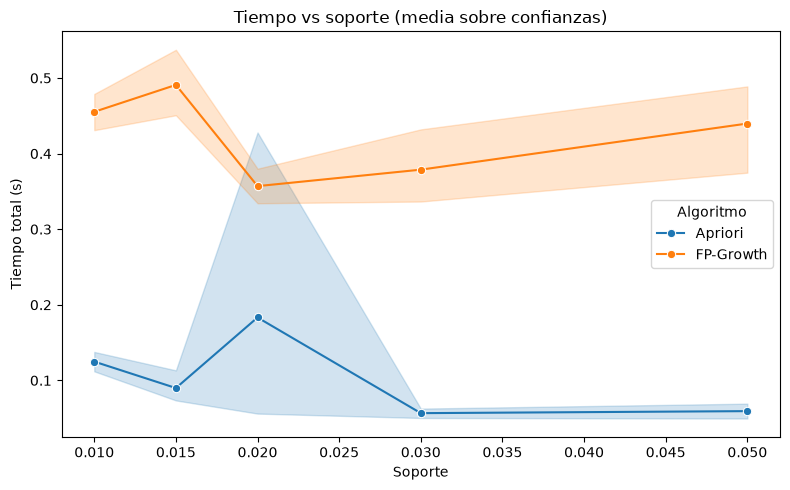

In [23]:
# Resume y visualiza la comparación de tiempos.
display(comparacion.groupby('Algoritmo')[['Tiempo_frecuentes_s','Tiempo_total_s','Conjuntos_frecuentes','Reglas']].agg(['mean','min','max']).round(4))
fig,ax=plt.subplots(figsize=(8,5))
sns.lineplot(data=comparacion,x='Soporte',y='Tiempo_total_s',hue='Algoritmo',marker='o',ax=ax)
ax.set(title='Tiempo vs soporte (media sobre confianzas)',xlabel='Soporte',ylabel='Tiempo total (s)')
plt.tight_layout(); plt.savefig(OUT/'comparacion_tiempos.png',dpi=160); plt.show()


## 9. Ocho preguntas del taller

In [24]:
# Convierte los códigos en nombres y muestra las reglas.
def nombres(items):
    return ', '.join(catalogo.get(str(x),str(x)) for x in sorted(items))

def mostrar_reglas(df,n=20):
    if df.empty:
        print('No se encontraron reglas con esos parámetros.')
        return pd.DataFrame()
    v=df.copy()
    v['SI'] = v.antecedents.apply(nombres)
    v['ENTONCES'] = v.consequents.apply(nombres)
    cols=['SI','ENTONCES','support','confidence','lift','leverage','conviction']
    display(v.sort_values('lift',ascending=False)[cols].head(n))
    return v


### Pregunta 1. Reglas de producto a producto (k=1)

In [25]:
# Muestra reglas con un producto por lado (k=1).
reglas_k1 = (reg_fp[(reg_fp['antecedents'].map(len)==1) & (reg_fp['consequents'].map(len)==1)]
             if not reg_fp.empty else pd.DataFrame())
r1=mostrar_reglas(reglas_k1,15)


No se encontraron reglas con esos parámetros.


### Pregunta 2. Diferencias Apriori/FP-Growth

In [26]:
# Compara tiempos y resultados de los dos algoritmos.
print('Apriori segundos:',round(ta_total,4),'FP-Growth segundos:',round(tf_total,4))
print('Coinciden conjuntos frecuentes:',a==b)


Apriori segundos: 0.1075 FP-Growth segundos: 0.4775
Coinciden conjuntos frecuentes: True


### Pregunta 3. Efecto del soporte y confianza

In [27]:
# Muestra cómo cambian tiempos y reglas con los parámetros.
display(comparacion.pivot_table(index=['Soporte','Confianza'],columns='Algoritmo',values=['Reglas','Tiempo_total_s']))


Reglas           Tiempo_total_s          
Algoritmo         Apriori FP-Growth        Apriori FP-Growth
Soporte Confianza                                           
0.010   0.20          0.0       0.0       0.135598  0.469991
        0.35          0.0       0.0       0.139733  0.487769
        0.50          0.0       0.0       0.104135  0.433037
        0.65          0.0       0.0       0.119929  0.430340
0.015   0.20          0.0       0.0       0.070655  0.557239
        0.35          0.0       0.0       0.120290  0.477683
        0.50          0.0       0.0       0.092268  0.491305
        0.65          0.0       0.0       0.076370  0.437210
0.020   0.20          0.0       0.0       0.063202  0.367440
        0.35          0.0       0.0       0.549469  0.391902
        0.50          0.0       0.0       0.068132  0.324171
        0.65          0.0       0.0       0.052094  0.344436
0.030   0.20          0.0       0.0       0.064485  0.321437
        0.35          0.0       0.0       0.046766  0.353248
        0.50          0.0       0.0       0.054565  0.382085
        0.65          0.0       0.0       0.060907  0.458287
0.050   0.20          0.0       0.0       0.068843  0.346442
        0.35          0.0       0.0       0.049350  0.451420
        0.50          0.0       0.0       0.069353  0.501379
        0.65          0.0       0.0       0.049839  0.459847

### Pregunta 4. Reglas potencialmente espurias

In [28]:
# Busca reglas potencialmente espurias.
if not reg_fp.empty:
    espurias=reg_fp[(reg_fp['lift']<=1.0) | ((reg_fp['support']<0.015)&(reg_fp['lift']<1.1))]
    mostrar_reglas(espurias,15)
else:
    print('Sin reglas para evaluar.')


Sin reglas para evaluar.


### Pregunta 5. Reglas k > 1

In [29]:
# Muestra reglas con varios productos antecedentes (k>1).
reglas_k_mayor = reg_fp[reg_fp['antecedents'].map(len)>1] if not reg_fp.empty else pd.DataFrame()
mostrar_reglas(reglas_k_mayor,15)


No se encontraron reglas con esos parámetros.


""


### Pregunta 6. Probabilidad de comprar A y B al azar

In [30]:
# Calcula la probabilidad observada y la esperada al azar.
if not reglas_k1.empty:
    regla = reglas_k1.sort_values('lift',ascending=False).iloc[0]
    p_a = float(regla['antecedent support']); p_b=float(regla['consequent support'])
    p_real=float(regla['support']); p_azar=p_a*p_b
    print('A:',nombres(regla['antecedents']),'| B:',nombres(regla['consequents']))
    print(f'P(A)={p_a:.6f}; P(B)={p_b:.6f}; bajo independencia={p_azar:.6f}')
    print(f'P(A y B) observada={p_real:.6f}; lift={regla["lift"]:.3f}')
else: print('Se necesita una regla k=1 para ilustrar el cálculo.')


Se necesita una regla k=1 para ilustrar el cálculo.


### Pregunta 7. Reglas interesantes

In [31]:
# Selecciona asociaciones interesantes por confianza y lift.
if not reg_fp.empty:
    interes=reg_fp[(reg_fp['lift']>1.2) & (reg_fp['confidence']>=0.30)].copy()
    mostrar_reglas(interes,20)
else: print('Sin reglas para seleccionar.')


Sin reglas para seleccionar.


### Pregunta 8. Comportamiento del consumidor
**Escribe aquí tu interpretación** según las reglas obtenidas: complementariedad, ocasión de compra y posibles limitaciones. No supongas causalidad.

## 10. Explorar combos entre más y menos vendidos

In [32]:
# Explora posibles combos entre productos populares y poco vendidos.
codigos_top10=set(top.head(10).index)
codigos_bajos=set(menores.head(30).index)
if not reg_fp.empty:
    combos=reg_fp[reg_fp.apply(lambda r: bool((set(r['antecedents'])|set(r['consequents']))&codigos_top10)
        and bool((set(r['antecedents'])|set(r['consequents']))&codigos_bajos),axis=1)]
    print('Reglas candidatas de alta/baja rotación:',len(combos))
    mostrar_reglas(combos,20)
else: print('No se pueden evaluar combos con el soporte actual.')


No se pueden evaluar combos con el soporte actual.


## 11. Guardar tablas

In [33]:
# Exporta reglas y resultados para el informe.
if not reg_fp.empty:
    guardado=reg_fp.copy()
    guardado['antecedents']=guardado['antecedents'].apply(nombres)
    guardado['consequents']=guardado['consequents'].apply(nombres)
    guardado.to_csv(OUT/'reglas_fp_growth.csv',index=False,encoding='utf-8-sig')
if not reg_ap.empty:
    guardado=reg_ap.copy()
    guardado['antecedents']=guardado['antecedents'].apply(nombres)
    guardado['consequents']=guardado['consequents'].apply(nombres)
    guardado.to_csv(OUT/'reglas_apriori.csv',index=False,encoding='utf-8-sig')
print('Archivos creados en:',OUT.resolve())


Archivos creados en: C:\Lab03__\lab03\resultados
